# Прогнозирование оттока клиентов банка (Bank Customer Churn Prediction)

**Номер команды:** 99

**Участники:**

* Атамогланов, БММ244

* Мартыненко, БММ244

* Дао, БММ243

## Описание данных

**Тема датасета:** информация о клиентах европейского банка, используется для прогнозирования оттока клиентов.

**Наблюдение:** один клиент банка.

**Источник данных:** датасет с платформы Kaggle "Bank Customer Churn Prediction". Автор данных - Murilo Zangari. Ссылка на датасет с данными: https://www.kaggle.com/datasets/murilozangari/customer-churn-from-a-bank?resource=download$0.

**Количество наблюдений:** 10 000

**Количество признаков:** 14 (13 предикторов + 1 целевая переменная `Exited`)

## Описание признаков

| Признак | Описание | Формат данных | Тип данных |
|---|---|---|---|
| RowNumber | порядковый номер строки | int64 | количественный дискретный |
| CustomerId | уникальный ID клиента | int64 | номинальный категориальный |
| Surname | фамилия клиента | object | номинальный категориальный |
| CreditScore | кредитный рейтинг клиента (может варьироваться с 300 до 850) | int64 | количественный дискретный |
| Geography | страна проживания клиента | object | номинальный категориальный |
| Gender | пол клиента | object | бинарный категориальный |
| Age | возраст клиента | int64 | количественный дискретный |
| Tenure | стаж обслуживания в банке, лет | int64 | количественный дискретный |
| Balance | остаток на счете | float64 | количественный непрерывный |
| NumOfProducts | количество продуктов банка у клиента | int64 | количественный дискретный |
| HasCrCard | наличие кредитной карты | int64 | бинарный категориальный |
| IsActiveMember | активность клиента | int64 | бинарный категориальный |
| EstimatedSalary | оценочная зарплата клиента | float64 | количественный непрерывный |
| Exited | целевая переменная - отток клиента | int64 | бинарный категориальный |

**Важно:** RowNumber, CustomerId и Surname являются техническими индексами, которые не несут кокакого-либо математического смысла и исключается из дальнейшего анализа.

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler


import warnings


warnings.filterwarnings('ignore')

df = pd.read_csv('Churn_Modelling.csv')


# Числовые (количественные) и категориальные/бинарные признаки
numeric_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
categorical_cols = ['Geography', 'Gender', 'HasCrCard', 'IsActiveMember', "Exited"]

df.shape

df.dtypes

RowNumber            int64
CustomerId           int64
Surname                str
CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

## Пропуски и дубликаты

### 1. Определение и замена

In [ ]:
# 1. Проверка на пропуски
df.isna().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [ ]:


# Замена пропусков подходящей МЦТ, результат — в НОВУЮ переменную
df_clean = df.copy()
df_clean[numeric_cols] = df_clean[numeric_cols].fillna(df_clean[numeric_cols].median())
df_clean[categorical_cols] = df_clean[categorical_cols].fillna(df_clean[categorical_cols].mode().iloc[0])

print(df_clean.isna().sum())  # проверка, что пропусков не осталось


RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


Для количественных признаков пропуски были заменены на соотвествующую **медианное значение** по данному признаку, так как медиана достаточно устойчива к выбросам (в отличие от той же средней).

Для категориальных признаков пропуски были заменены на соотвествующую **значение моды** по данному признаку, так как иные показатели (среднее, медиана) не имеют никакого математического смысла



### 2. Определение и дубликатов

In [ ]:
# 2. Проверка дубликатов
df_clean.duplicated().sum()

np.int64(0)

In [ ]:


# Удаление полных дубликатов — тоже в df_clean
df_clean = df_clean.drop_duplicates()

print(df_clean.duplicated().sum())  # проверка, что дубликатов не осталось

0


Также для валидности использования наших данных в дальнейшем анализе, были удалены полные дубликаты наблюдений в датасете. Новый датасет без дубликатов сохранен по названием ```df_clean```.  Дальнейший анализ будет проведен с данным датасетом.







## Выбросы

### 1. Определение выбросов

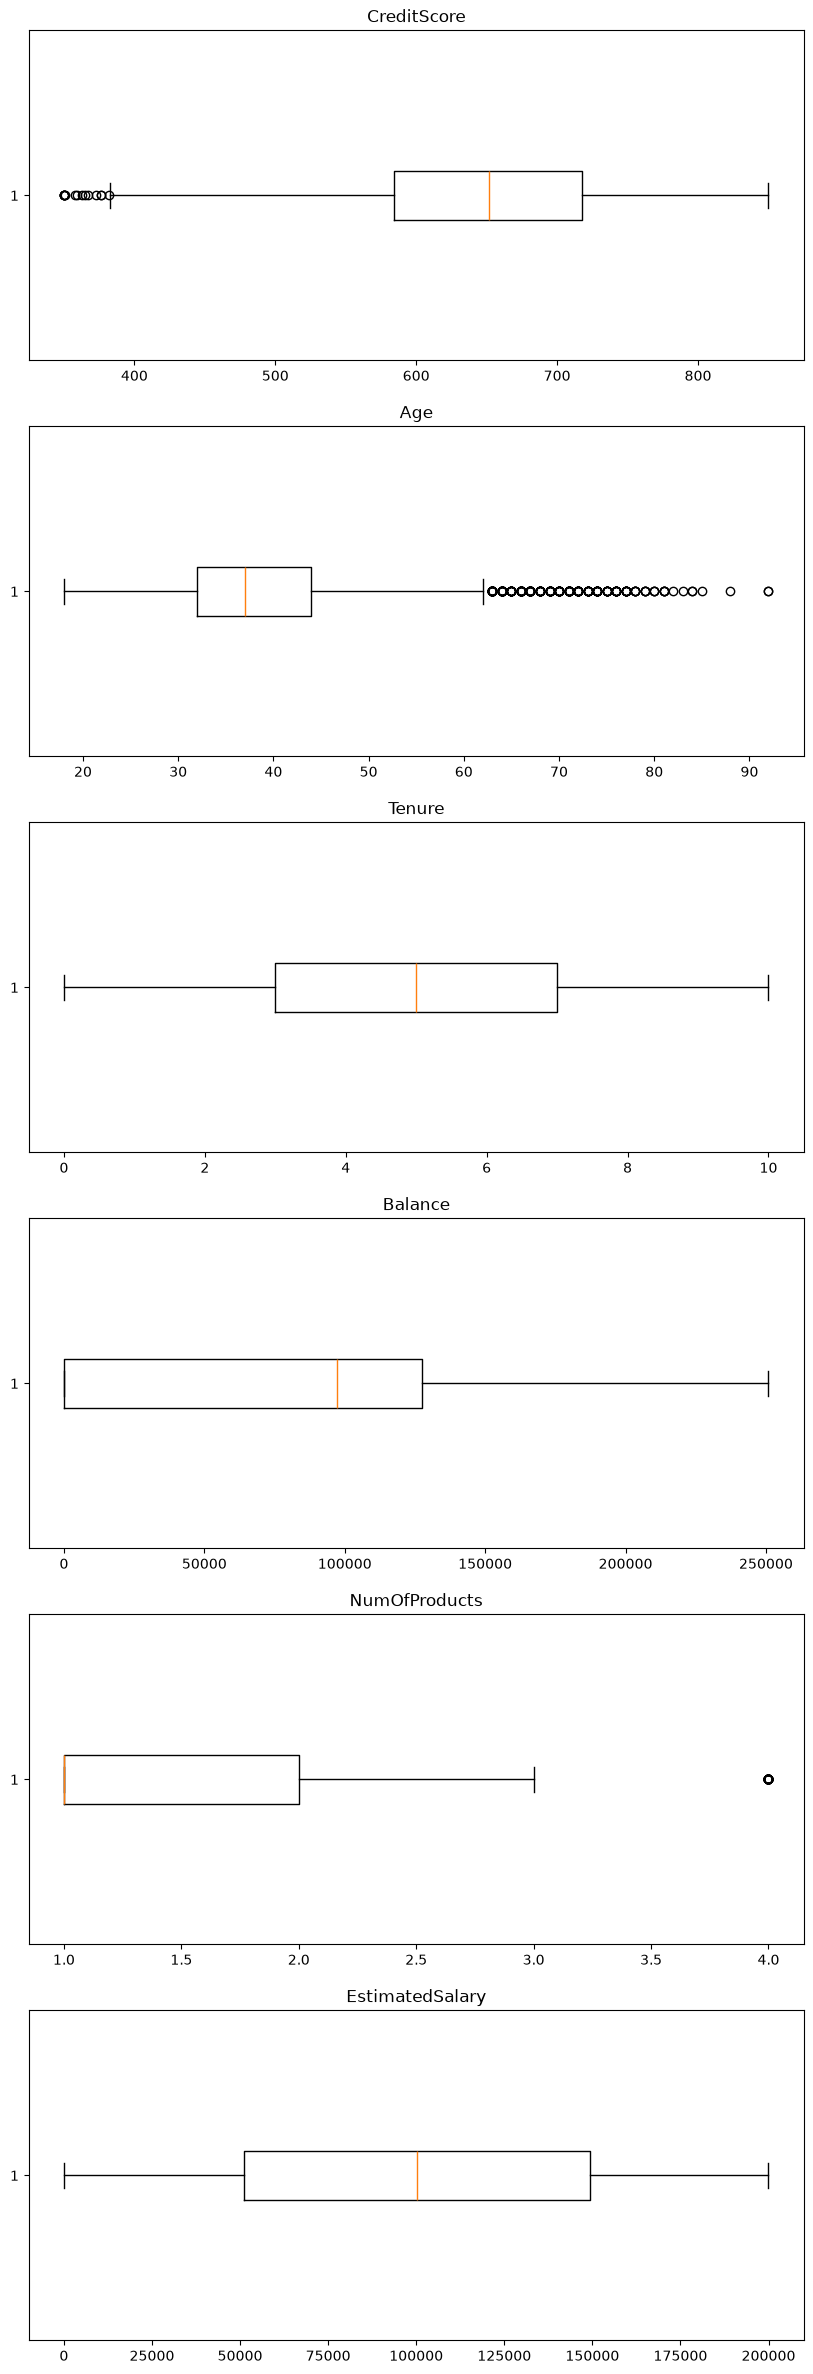

In [ ]:
#для определения выбросов в сформируем ящики с усами

fig, ax = plt.subplots(len(numeric_cols), 1, figsize=(10, 30))  # создаем сетку графиков с 1 строкой и n столбцами
                                                               #(n - кол-во количественных признаков)

for i in range(len(numeric_cols)):
    ax[i].set_title(numeric_cols[i]) # добавляем заголовки на графики (по каждому количественному признаку)
    ax[i].boxplot(df_clean[numeric_cols[i]], vert=False) # рисуем ящики с усами

В данном случае можно увидеть, что выбросы имеются по следующим количественным признаками:

1. **CreditScore** - кредитный рейтинг клиента
2. **Age** - возраст клиента (есть явное ассиметричное распределение со скосом большей массы данных влево)
3. **NumOfProduct** - количество продуктов банка у клиента

Но перед очисткой нужно понять следующее: **являются ли эти данные выбросами на самом деле или же это реальные клиенты, которые имеют информативную значимость (в дальнейшем для обучения линейной модели)?**

Для ответа на данный вопрос следует рассмотреть каждую из вышеперечисленных колличественных признаков:

#### 1.1 Гистограмма распределения

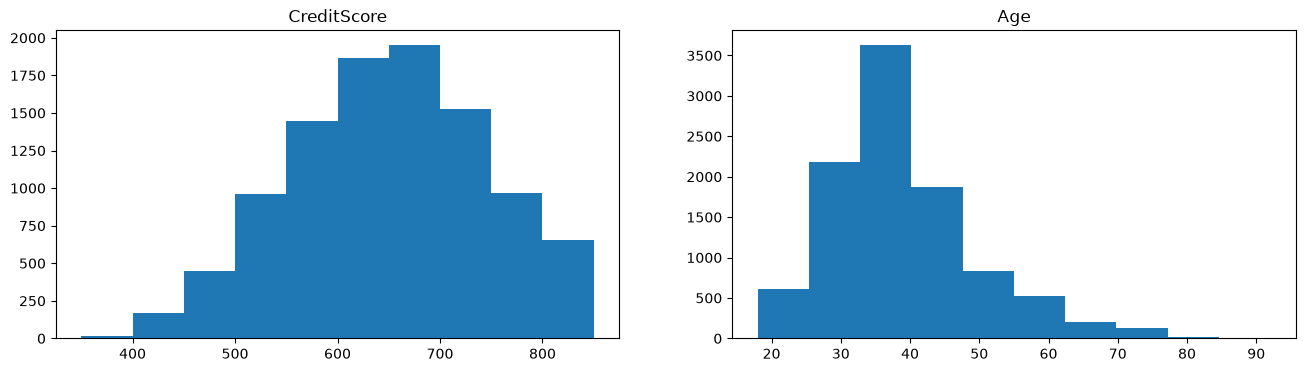

In [ ]:

lst = ["CreditScore", "Age"]

fig, ax = plt.subplots(1, 2, figsize=(16, 4)) # создаем сетку графиков с 1 строкой и 4 столбцами (для каждого признака в lst)
for i in range(len(lst)):
    ax[i].set_title(lst[i]) # добавляем заголовки на графики
    ax[i].hist(df_clean[lst[i]]) # рисуем гистограммы



Отдельно рисуем для NumOfProducts поскоольку он не является непрерывнной переменной

<Axes: xlabel='NumOfProducts'>

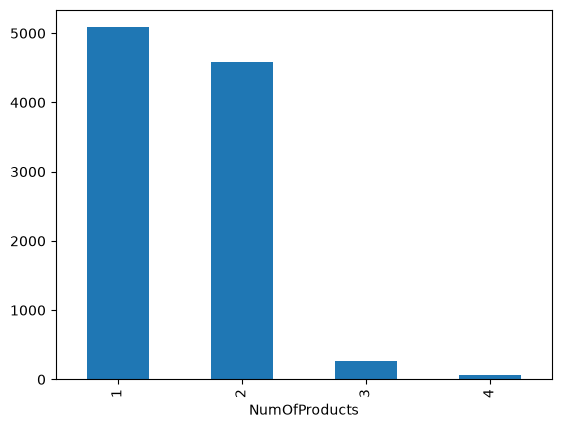

In [ ]:
df_clean.NumOfProducts.value_counts().sort_index().plot(kind = "bar")

Для того, чтобы понять как работать с выбросами и для каких признаков релевантна очистка от выбросов, были построены гистограммы распределения по каждому из количественных признаков.

Начнем с самого заметного: ```NumOfProducts```. Вспомним, что признак дискретный и по этой причине он принимает только строгие целые значения, тогда как методы IQR и стандартных отклонений разработаны для непрерывных величин, из-за чего становится нерелевантно использовать очистку (так как каждое из значений уникально, а не является случайной ошибкой + таких уникальных значений мало: всего 4, в сравнении с тем же `Age`).

При этом количество значений по данному признаку довольно мало (всего 4 значения), что позволяет перевести данный признак из количественнных в категориальный.

---
**Зачем?**. Значение "4 продукта" не является выбросом (как может показаться на первый взгляд из ящика с усами), который, если оставить признак количественным, линейная модель может воспринять как ошибку (выброс) из-за редкости значения. Разница между 1 и 2 продуктами не равно разнице между 3 и 4 соотвественно.

#### 1.2 Перевод ```NumOfProducts``` из количественных в категориальные

In [ ]:
#  (×﹏×)  ----- эх, прощай друг, NumOfProducts  -----  (×﹏×)

def g(x):
    if x == 1:
        return "1"
    if x == 2:
        return "2"
    if x == 3 or x == 4:
        return "3+"

df_clean['NumOfProducts_category'] = df_clean['NumOfProducts'].apply(g)

df_clean


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,NumOfProducts_category
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,3+
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,2
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0,2
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0,1
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1,2


Перевод из количесвтенных в категориальные был совершен следующим образом:

- Значения с 1 и 2 были переведены в соотвественные категориальные значения "1" и "2"

- Значения 3 и 4 были объединены в одно категориальное значение "3+" (так как значения 3 и 4 довольно редко встречаются)

Новые значения сохранены в признак ```NumOfProducts_category``` в датафрейме ```df_clean```


#### 1.3 ```CreditScore``` и релевантность очистки

In [ ]:
print (f'Минимальное значение по CreditScore: {df_clean["CreditScore"].min()}')


Минимальное значение по CreditScore: 350


Для проверки ```CreditScore``` на релевантность очистки было принято решение посмотреть на минимальное значение по данному показателю, чтобы понять является ли крайнее левое значение на самом деле "выбросом".

По итогу минимальное значение получилось 350 баллов. Если мы обратимся к разделу "Описание признаков", то можем увидеть, что ```CreditScore``` может варьироваться с 300 до 850 баллов. Следовательно, у нас нет оснований удалять данные, которые не входят в усы ящика, так как они в том числе обладают информационной значимостью для обучения линеной модели.

Если посчитать по формуле $Q1 - 1.5 \times IQR$, левая граница «уса» равна 383 баллам. В датасете ровно 15 клиентов имеют рейтинг ниже 383 (включая тех, у кого 350). И самое главное: все 15 из 15 этих клиентов ушли из банка (Exited = 1, 100% отток)!

Если мы удалим этих клиентов, модель просто потеряет важнейшую закономерность: клиенты с критически низким кредитным рейтингом гарантированно покидают банк.



#### 1.4 ```Age``` и релевантность очистки

<Axes: xlabel='Age'>

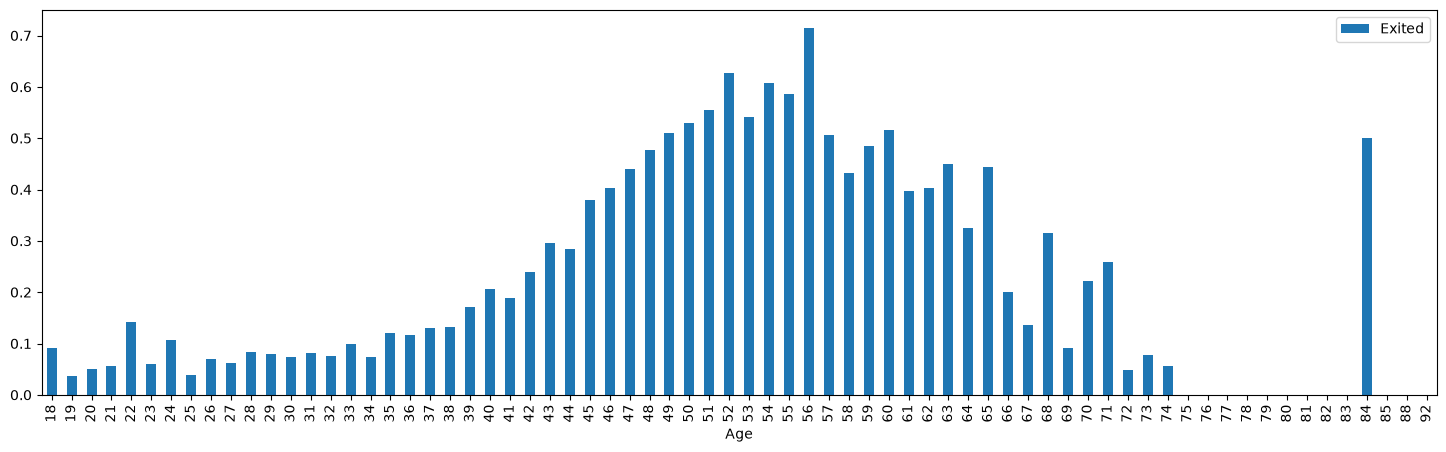

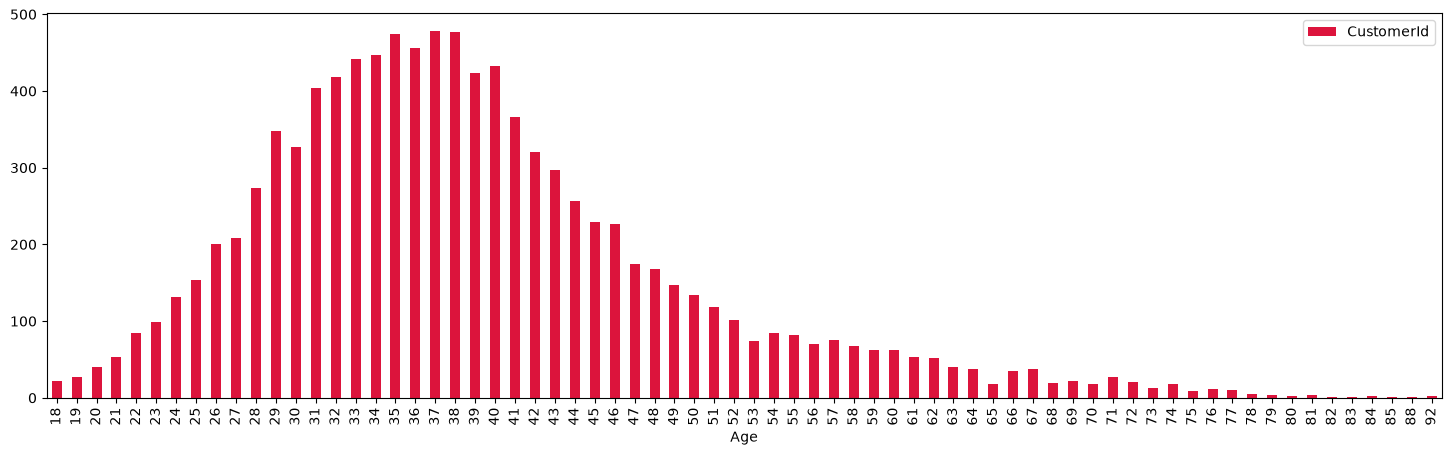

In [ ]:


bg = df_clean.pivot_table(index="Age", values="Exited", aggfunc="mean")

bd = df_clean.pivot_table(index="Age", values="CustomerId", aggfunc="count")

bg.plot(y='Exited', kind='bar', figsize=(18, 5))

bd.plot(y='CustomerId', kind='bar', figsize=(18, 5), color= 'crimson')


Перейдем к самому интересному - ```Age```. По ящику с усами видна длинная область "кружков" справа. Неужели это все выбросы? Давайте разбираться.

Для начала были построены две столбчатые диаграммы: первая (синия) показывает долю ушедших из банка клиентов (Exited = 1) на каждый представленный возраст. Вторая (красная) отображает абсолютное количество клиентов банка для каждого возраста. С первого графика может показаться что значниий по доле оттока у более пожилых клиентов просто нет (начиная с 75 лет), однако красный график показвывает почемиу так происходит: количество пожилых слишком мало и абсолютное большинство из них сотаются лояльными к банку (Exited = 0).

Скачок в 84 года связан с тем, что 84-летних очень мало, и если найдется несколько ушедших клиентов из общей массы представителей данного возраста, то  и их доля будет внушающей.

Да, пожилых мало, но и удалять их не стоит, так как в общей сумме они представляют из себя категорию лояльных клиентов, что также информационно значимо для обучения модели.

Однако, для понимания значимости данной категории для модели, следует провести еще одно исследование: рассмотреть качество модели логистической регрессии на очищенных от выбросов данных и без них:

ROC-AUC очищенная: 0.729
ROC-AUC не очищенная: 0.738


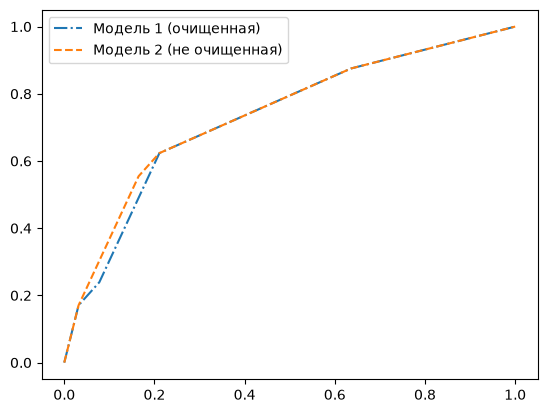

In [ ]:
def g(x):
    if 18 <= x <= 33:
        return "18-33"
    elif 34 <= x <= 42:
        return "34-42"
    elif 43 <= x <= 51:
        return "43-51"
    elif 52 <= x <= 59:
        return "52-59"
    else:
        return "60+"


df_train, df_test = train_test_split(df_clean, test_size=0.2, random_state=42)

df_train_clean = df_train.copy()

a = ["Age"]

for i in a:
    q1 = df_train_clean[i].quantile(0.25)
    q3 = df_train_clean[i].quantile(0.75)
    IQR = q3 - q1
    left = q1 - 1.5 * IQR
    right = q3 + 1.5 * IQR
    df_train_clean = df_train_clean[df_train_clean[i].between(left, right)]

df_train_clean['Age_Category'] = df_train_clean['Age'].apply(g)
df_train['Age_Category'] = df_train['Age'].apply(g)
df_test['Age_Category'] = df_test['Age'].apply(g)

cats = ["18-33", "34-42", "43-51", "52-59", "60+"]

# Заставляем Pandas запомнить, что группа "60+" существует, даже если сейчас в таблице таких людей нет
df_train_clean['Age_Category'] = pd.Categorical(df_train_clean['Age_Category'], categories=cats)
df_train['Age_Category'] = pd.Categorical(df_train['Age_Category'], categories=cats)
df_test['Age_Category'] = pd.Categorical(df_test['Age_Category'], categories=cats)

#-----------------------------------------------------------------------------------------------------


df_train_clean_onehot = pd.get_dummies(df_train_clean, columns = ['Age_Category'], dtype=int, drop_first= True)

df_train_no_clean_onehot = pd.get_dummies(df_train, columns = ['Age_Category'], dtype=int, drop_first= True)

df_test_onehot = pd.get_dummies(df_test, columns = ['Age_Category'], dtype=int, drop_first= True)

#-----------------------------------------------------------------------------------------------------

categories = ["Age_Category_34-42", "Age_Category_43-51", "Age_Category_52-59", "Age_Category_60+"]


X1_train = df_train_clean_onehot[categories]
y1_train = df_train_clean_onehot["Exited"]

X2_train = df_train_no_clean_onehot[categories]
y2_train = df_train_no_clean_onehot["Exited"]

X_test = df_test_onehot[categories]
y_test = df_test_onehot["Exited"]

#-----------------------------------------------------------------------------------------------------

model1_clean = LogisticRegression().fit(X1_train, y1_train)

model2_not_clean = LogisticRegression().fit(X2_train, y2_train)

y_pred_proba1_clean = model1_clean.predict_proba(X_test)

y_pred_proba2_not_clean = model2_not_clean.predict_proba(X_test)

#-----------------------------------------------------------------------------------------------------

fpr1, tpr1, thresholds = roc_curve(y_test, y_pred_proba1_clean[:, 1])  # модель 1
fpr2, tpr2, thresholds = roc_curve(y_test, y_pred_proba2_not_clean[:, 1])  # модель 2

plt.plot(fpr1, tpr1, ls = '-.', label = 'Модель 1 (очищенная)')
plt.plot(fpr2, tpr2, ls = '--', label = 'Модель 2 (не очищенная)')
plt.legend()  # выводим легенду


print("ROC-AUC очищенная:", round(roc_auc_score(y_test, y_pred_proba1_clean[:, 1]), 3))
print("ROC-AUC не очищенная:", round(roc_auc_score(y_test, y_pred_proba2_not_clean[:, 1]), 3))




В данном случае мы захотели сравнить качество двух моделей:

1. Модель 1 (очищенная от выбросов по Age)

2. Модель 2 (не очищенная от выбросов по Age)

Но для обучения модели нужно обратить внимание на самое распределение значений по ```Age``` - оно *не является линейной прямой*, тогда как логистическая регрессия предполагает линейную зависимость. По этой причине  значения ```Age``` были разделены на возрастные группы, для того чтобы модель могла не назначать один вес для всех значений признака, а индивидуальный вес для каждой возрастной группе по форме ее поведения (растет / падает / стабильно). Это позволит прогнозам модели повторятьь форму реальных данных.

---

Разделение на возрастные группы было проведено визуально-аналитическим методом:

* ```18-33``` - это клиенты с низкой долей оттока, без какого-либо ярко выраженного восходящего тренда.

* ```34-42``` - это зона умеренного роста по доле оттока, который плавно поднимается с 10% до 20%. Можно еще назвать эту зону областью умеренного риска.

* ```43-51``` - здесь происходит страмительный рост по доле оттока, который поднимается с 20% до 50%.

* ```52–59``` - это пиковая зона по доле оттока: доходит до 70%.

* ```60+``` - после 60 количество клиентов начинает страмительно падать. Именно из-за такого падения количества клиентов, синий график показывает хаотичные скачки и падения. Обьединение всех после 60, позволять сгладить уровень шума в данном диапозоне и сформировать, хотя и небольшую, но категорию с паттерном на лояльнось банку (в большинстве).

Использование квантильного деления на возрастные группы нерелевантно в данном случае, так как из-за четкого деления клиентов по одинаковым (по кол-ву чел.) группам, в один список  могут попасть, например, 43-летние (у которых доля ухода 0.25) и 56-летние (у которых доля ухода более 0.7). Из-за этого информация о доле ушедших по данной группе сильно искажается (риск ухода 56-летних недооценивается и т.д).

---

Далее датафрейм был разделен на на тестовую и тренировочную. Тренировочных моделей в свою очерь было 2:

1) ```df_train_clean``` - очищенная от выбросов по Age (по методу 1.5 IQR)

2) ```df_train``` - не очищенная от выбросов по Age


---

После обучения моделей оба из них сравнили с естественной средой (```df_test``` - тестовая выборка) для определения качество модели. Метрикой качетва моделей была выбрана ROC-AUC score, так как ROC-AUC оценивает баланс между True Positive Rate (охват реального оттока) и False Positive Rate (ложные тревоги), поэтому дисбаланс выборки не позволяет обмануть метрику.

По итогу, были получены следующие значения:

1) ROC-AUC по модели 1: 0.729

2) ROC-AUC по модели 2: 0.738

Математически модель 2 лучше модели 1. Следовательно у нас оснований очищать данные по ```Age```.

*Примечание:* перед обучением моделей не использовалось масштабирование данных и предикторами при этом только были возрастные группы.



### 2. Вывод

Проведенный выше в пункте 1 анализ показал, что необходимости удалять выбросы нет.

Дальнейший анализ все еще проходит с датафреймом ```df_clean```.

## Визуализация

### 1. Гистограммы количественных признаков

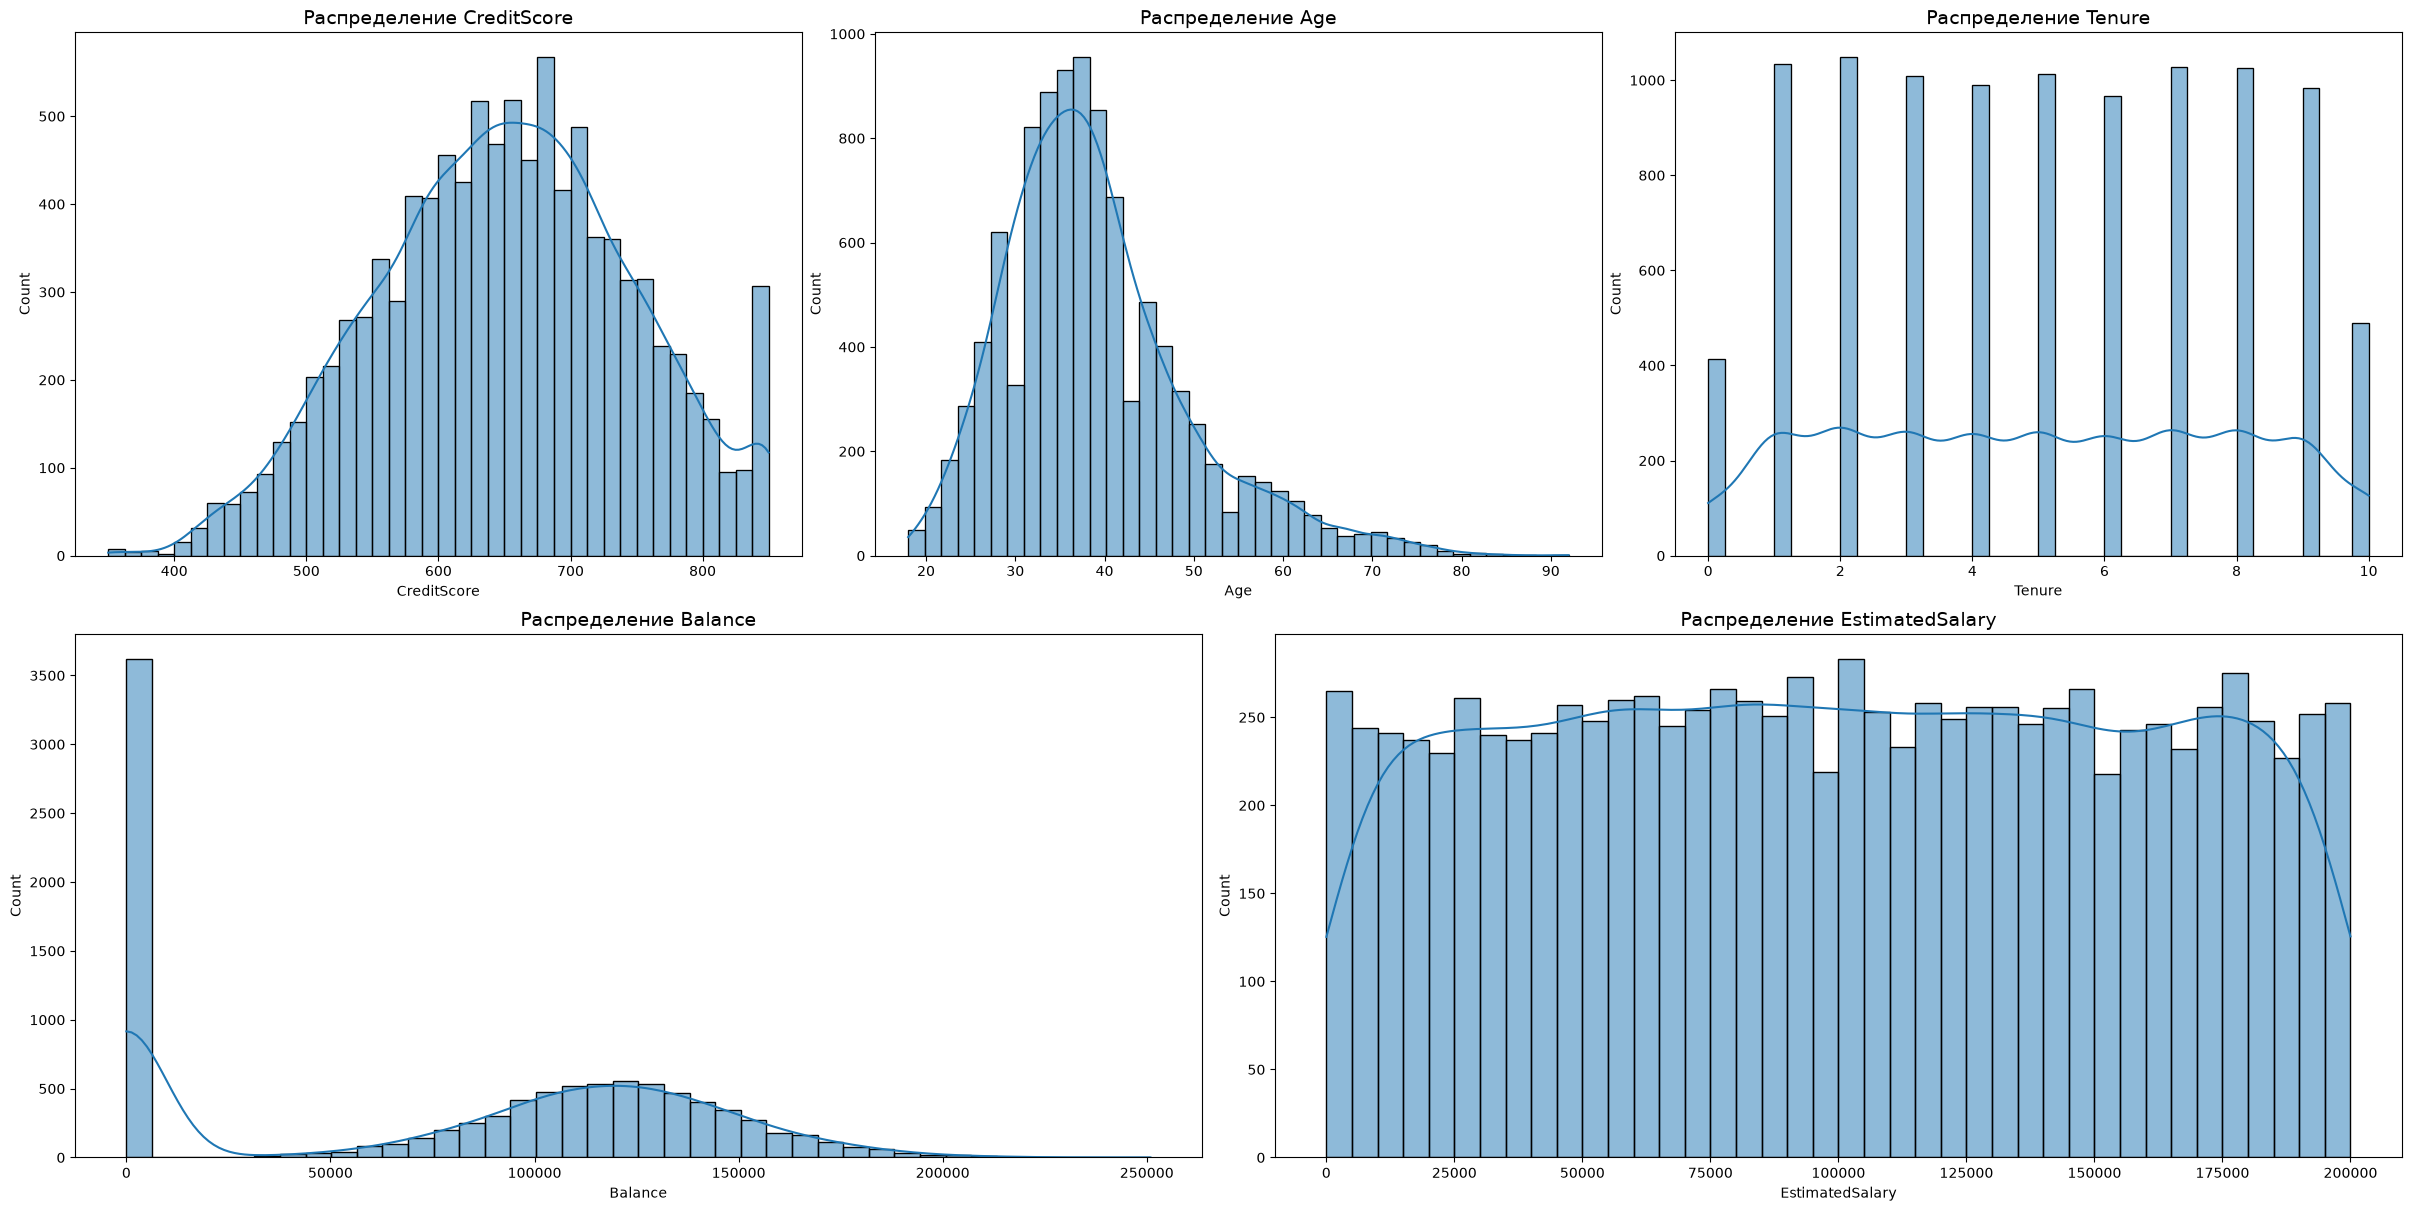

In [ ]:
df_clean_new = df_clean.drop('NumOfProducts', axis=1) # удаляем NumOfProducts из количественных признаков, теперь он категориальный

numeric_cols_new = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary'] # новый список количественных признаков


import matplotlib.gridspec as gridspec
fig = plt.figure(figsize=(24, 12), constrained_layout=True)
gs = gridspec.GridSpec(2, 6, figure=fig)

ax0 = fig.add_subplot(gs[0, 0:2])
ax1 = fig.add_subplot(gs[0, 2:4])
ax2 = fig.add_subplot(gs[0, 4:6])

ax3 = fig.add_subplot(gs[1, 0:3])
ax4 = fig.add_subplot(gs[1, 3:6])
axes = [ax0, ax1, ax2, ax3, ax4]

for i in range(len(numeric_cols_new)):
    sns.histplot(df_clean_new[numeric_cols_new[i]], bins=40, kde=True, ax=axes[i])
    axes[i].set_title(f"Распределение {numeric_cols_new[i]}", fontsize=14)

Начнем с визуализации количественных признаков. Перед этим из ```df_clean``` был удален признак **NumOfProducts** (чтобы больше нам не мешал, так как теперь он отнесен к категориальным). Новый датафрейм сохранен с переменную ```df_clean_new```. Дальнейший анализ проводится с данным датафреймом.

Теперь перейдем к основным выводам по оставшимся количественным признакам:

1. ```CreditScore``` - распределение близко к нормльному с небольшой скошенностью влево. Визуально основная доля значений располагается приблизительно с 600 до 700.
Также можно заметить бимодальность распределения: имеется второй пик в самом конце распределения. И здесь самое интересное не то, что он есть, а почему он возник: строгие рамки значений. Как известно из раздела "Описание признаков" данные по анному признаку ограничены диапозон от 300 до 850. Следовательно, вся группа людей, у которых рейтинг математически мог быть еще выше 850 баллов, тоже располагаются на анной границе из-за чего мода образовалась *искуственно*.

2. ```Age``` - у распределения есть четко выраженная правосторонняя ассиметрия. Визуально основная доля значений располагается приблизительно с 30 до 40.

3. ```ln_Age``` - для решения проблемы правосторонней ассиметрии в пример приведено прологарифмированное распределение признака Age. И действительно, распределение стало очень близко похожим к нормальному.

4. ```Tenure``` - по распределению можно сразу понять что **Tenure** - признак дискретный. Значения почти равномерно распреелены от 1 до 9. Характерной особенностью является то, что количество клиентов с крайними значениями (0 и 10 лет) примерно в два раза меньше, чем в любой другой год.

5. ```Balance``` -  здесь явно выражена уже бимодальность. Первая мода - всплеск значений на уровне 0/близкому к 0. Вторая мода - располагается в диапозоне от 100 000 до 150 000. Второе распрделение на гистограмме близко к нормальному.

6. ```EstimatedSalary``` - наиболее равномерное распределение, среди представленных. Отсутствуют выраженные пики или скошенности. Количество клиентов с любой предполагаемой зарплатой в этом интервале примерно одинаково, из-за чего линия KDE выглядит почти горизонтальной.

*Примечание*: линия KDE необходима для более четкого выявления пиков (мод распределений) и независимости от кол-ва bins

### 2. Cтолбчатые диаграммы категориальных признаков

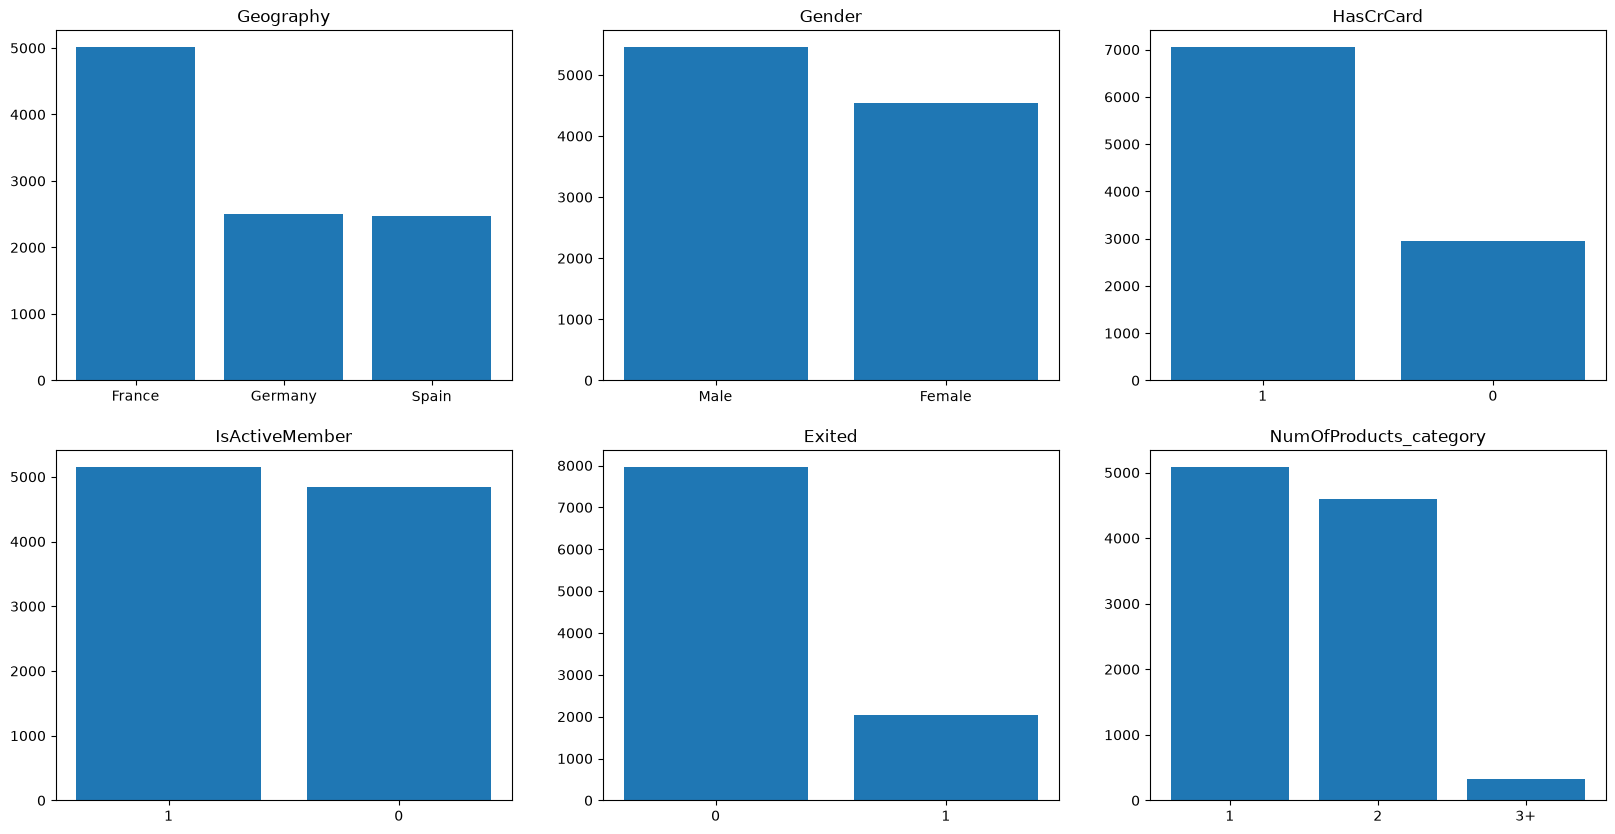

In [ ]:
categorical_cols_new = ['Geography', 'Gender', 'HasCrCard', 'IsActiveMember', "Exited", "NumOfProducts_category"] # новый список категориальных признаков


df_prob = df_clean_new.copy() # датафрейм df_prob создан чтобы не навредить основному в дальнейшей работе датафрейму df_clean_new


fig, ax = plt.subplots(2, 3, figsize=(20, 10))

ax = ax.flatten()

for i in range(len(categorical_cols_new)):

    ax[i].set_title(categorical_cols_new [i])
    freq = df_prob[categorical_cols_new [i]].value_counts()

    ax[i].bar(freq.index.astype(str), freq.values) # рисуем столбчатые диаграммы



Основные выводы по категориальным признакам:

1. ```Geography``` -  из диаграммы видно, что подавляющее число клиентов банка (почти 5000 чел.) из Франции. Далее почти на равне идут клиенты из Германии и Испании соответственно (около 2500 в каждой стране)

2. ```Gender``` -  поавляющее число клиентов банка - мужчины (более 5000 чел.). Далее уже идут женщины

3. ```HasCrCard``` - около 7000 клиентов банка имеют собственную креитную карточку, остальные 3000 - нет.

4. ```IsActiveMember``` - более 5000 клиентов банка являются "активными  клиентами", остальная часть - нет.

5. ```Exited``` - подавляющее большинство клиентов банка (почти 8000 чел.) еще не перестали пользоваться услугами банка. И около 2000 клиентов уже перестали пользоваться данным банком.

6. ```NumOfProducts_category``` - около 50% клиентов пользуются 1 продуктом банка, , около 45% клиентов - 2 проуктами, и менее 5% - 3 и более.

### 3. Скрипичные графики

#### 3.1 По количественным признакам

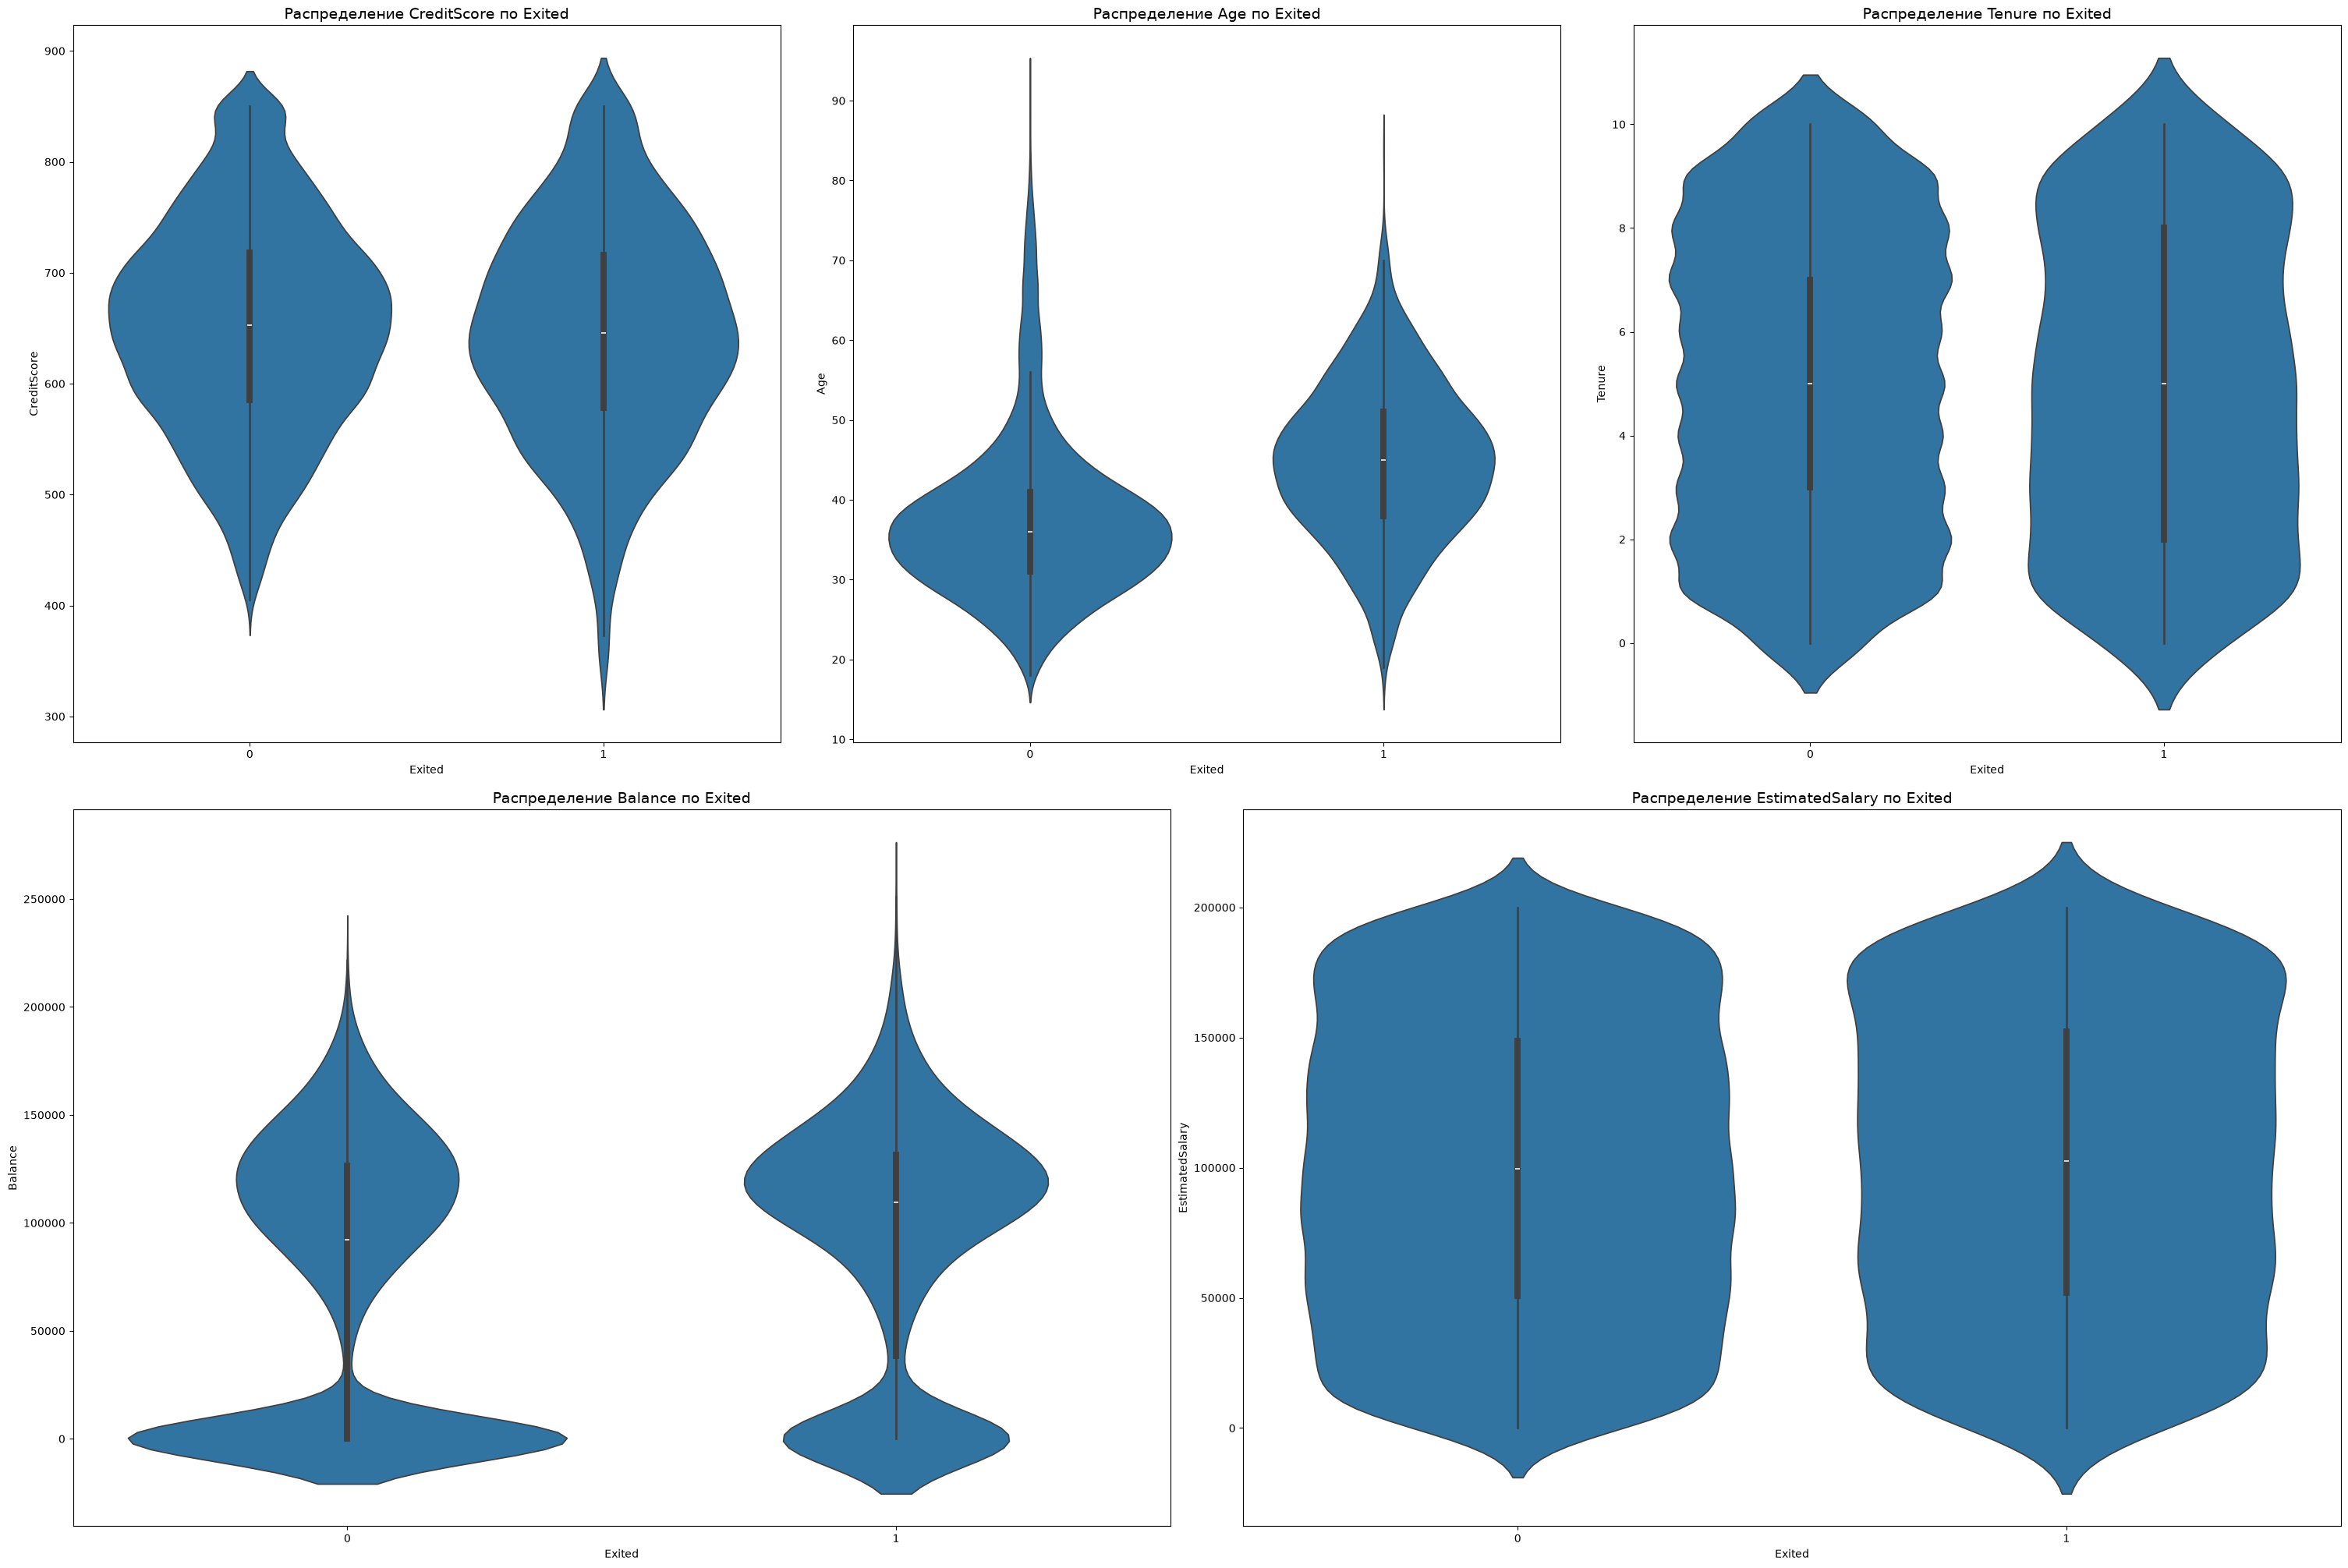

In [ ]:

fig = plt.figure(figsize=(30, 20), constrained_layout=True)
gs = gridspec.GridSpec(2, 6, figure=fig)

# Верхний ряд: 3 графика (занимают по 2 деления из 6)
ax0 = fig.add_subplot(gs[0, 0:2])
ax1 = fig.add_subplot(gs[0, 2:4])
ax2 = fig.add_subplot(gs[0, 4:6])

# Нижний ряд: 2 графика (занимают по 3 деления из 6, растягиваясь на всю строку)
ax3 = fig.add_subplot(gs[1, 0:3])
ax4 = fig.add_subplot(gs[1, 3:6])

axes = [ax0, ax1, ax2, ax3, ax4]

for i in range(len(numeric_cols_new)):
    axes[i].set_title(f'Распределение {numeric_cols_new[i]} по Exited', fontsize=14)
    sns.violinplot(x='Exited', y=numeric_cols_new[i], data=df_prob, ax=axes[i])




Далее в анализе команда решила проанализировать зависимости между целевым признаком и колличественными / качественными параметрами. Для анализа и визуализации данной зависимости между признаками идеально подойдет "скрипичный график", так как он позволяет отражать реальную форму данных, распределение в зависимости от установленного параметра (позволяет видеть как меняется распределение при изменении значения параметра). Тем сам были проитерпретированы следующие зависимости межу целевый признаком ```Exited``` и количественными признаками, расмотренные ранее в разделе **Визуализация**: **Гистограммы количественных признаков**

Основные выводы:

1. ```CreditScore``` и ```Exited``` - достаточно похожая форма скрипок у ушедших (1) и оставшихся (0) клиентов банка. Также медиана у тех и у других практически идентична. У обеих типов клиентов пик приходится на диапозон от 600 до 700 баллов и вторая мода на 850 баллов (у оставшихся клиентов вторая мода выражена чуть более заметно). Также можно заметить, что у ушедших клиентов нижний хвост достигает значения в 300 баллов - то есть уход мог быть связан и с низиким кредитным рейтингом. Но так как распределение показывает что, это совсем маленькая доля из всех ушедших клиентов, можно сделать вывод: **кредитный рейтинг не является значимым фактором, влияющим на отток**.

2. ```Age``` и ```Exited``` - здесь прослеживаются различия между ушедшими и оставшимися клиентами. Пик оставшихся клиентов расположен в диапозоне от 30 до 40 лет, тогда как у ушедших - от 40 до 50. Медиана у ушедших также выше, чем у оставшихся. Также можно заметить, что у оставшихся клиентов верхний хвост длинее и растягивается аж до 90 летних. Поведение данной незначительной доли клиентов можно объяснить следующим: люди в пожилом возрасте более консервативны и стабильныи и поэтому не меняют банк из-за какой-либо материальной, эмоциональной выгоды. Можно сделать вывод: **возраст достаточно сильно влияет на отток. Банк в основном теряет клиентов среднего возраста**.


3. ```Tenure``` и ```Exited``` - почти одинаковые формы скрипок у обеих групп клиентов. Медиана тоже почти идентичная. Вывод: **стаж обслуживания в банке никак не влияет на отток**.

4. ```Balance``` и ```Exited``` - здесь также прослеживаются различия между группами клиентов. Медиана у ушедших выше, чем у оставшихся. Также у оставшихся клиентов имеет сильный пик значений на нулевом балансе, тога как у ушедших клиентов основная масса значений расположена в диапозоне от 100 000о 150 000. Основной вывод здесь: **остаток счета значительно влияет на отток клиентов**. Может быть это связано с тем, что у ушеших клиентов были достаточно невыгодные условия по депозитам.

5. ```EstimatedSalary``` и ```Exited``` - почти одинаковые формы скрипок у обеих групп клиентов. Медиана тоже почти идентичная. Вывод: **оценочная запрлата клиента никак не влияет на отток**.

#### 3.2 По категориальным признакам

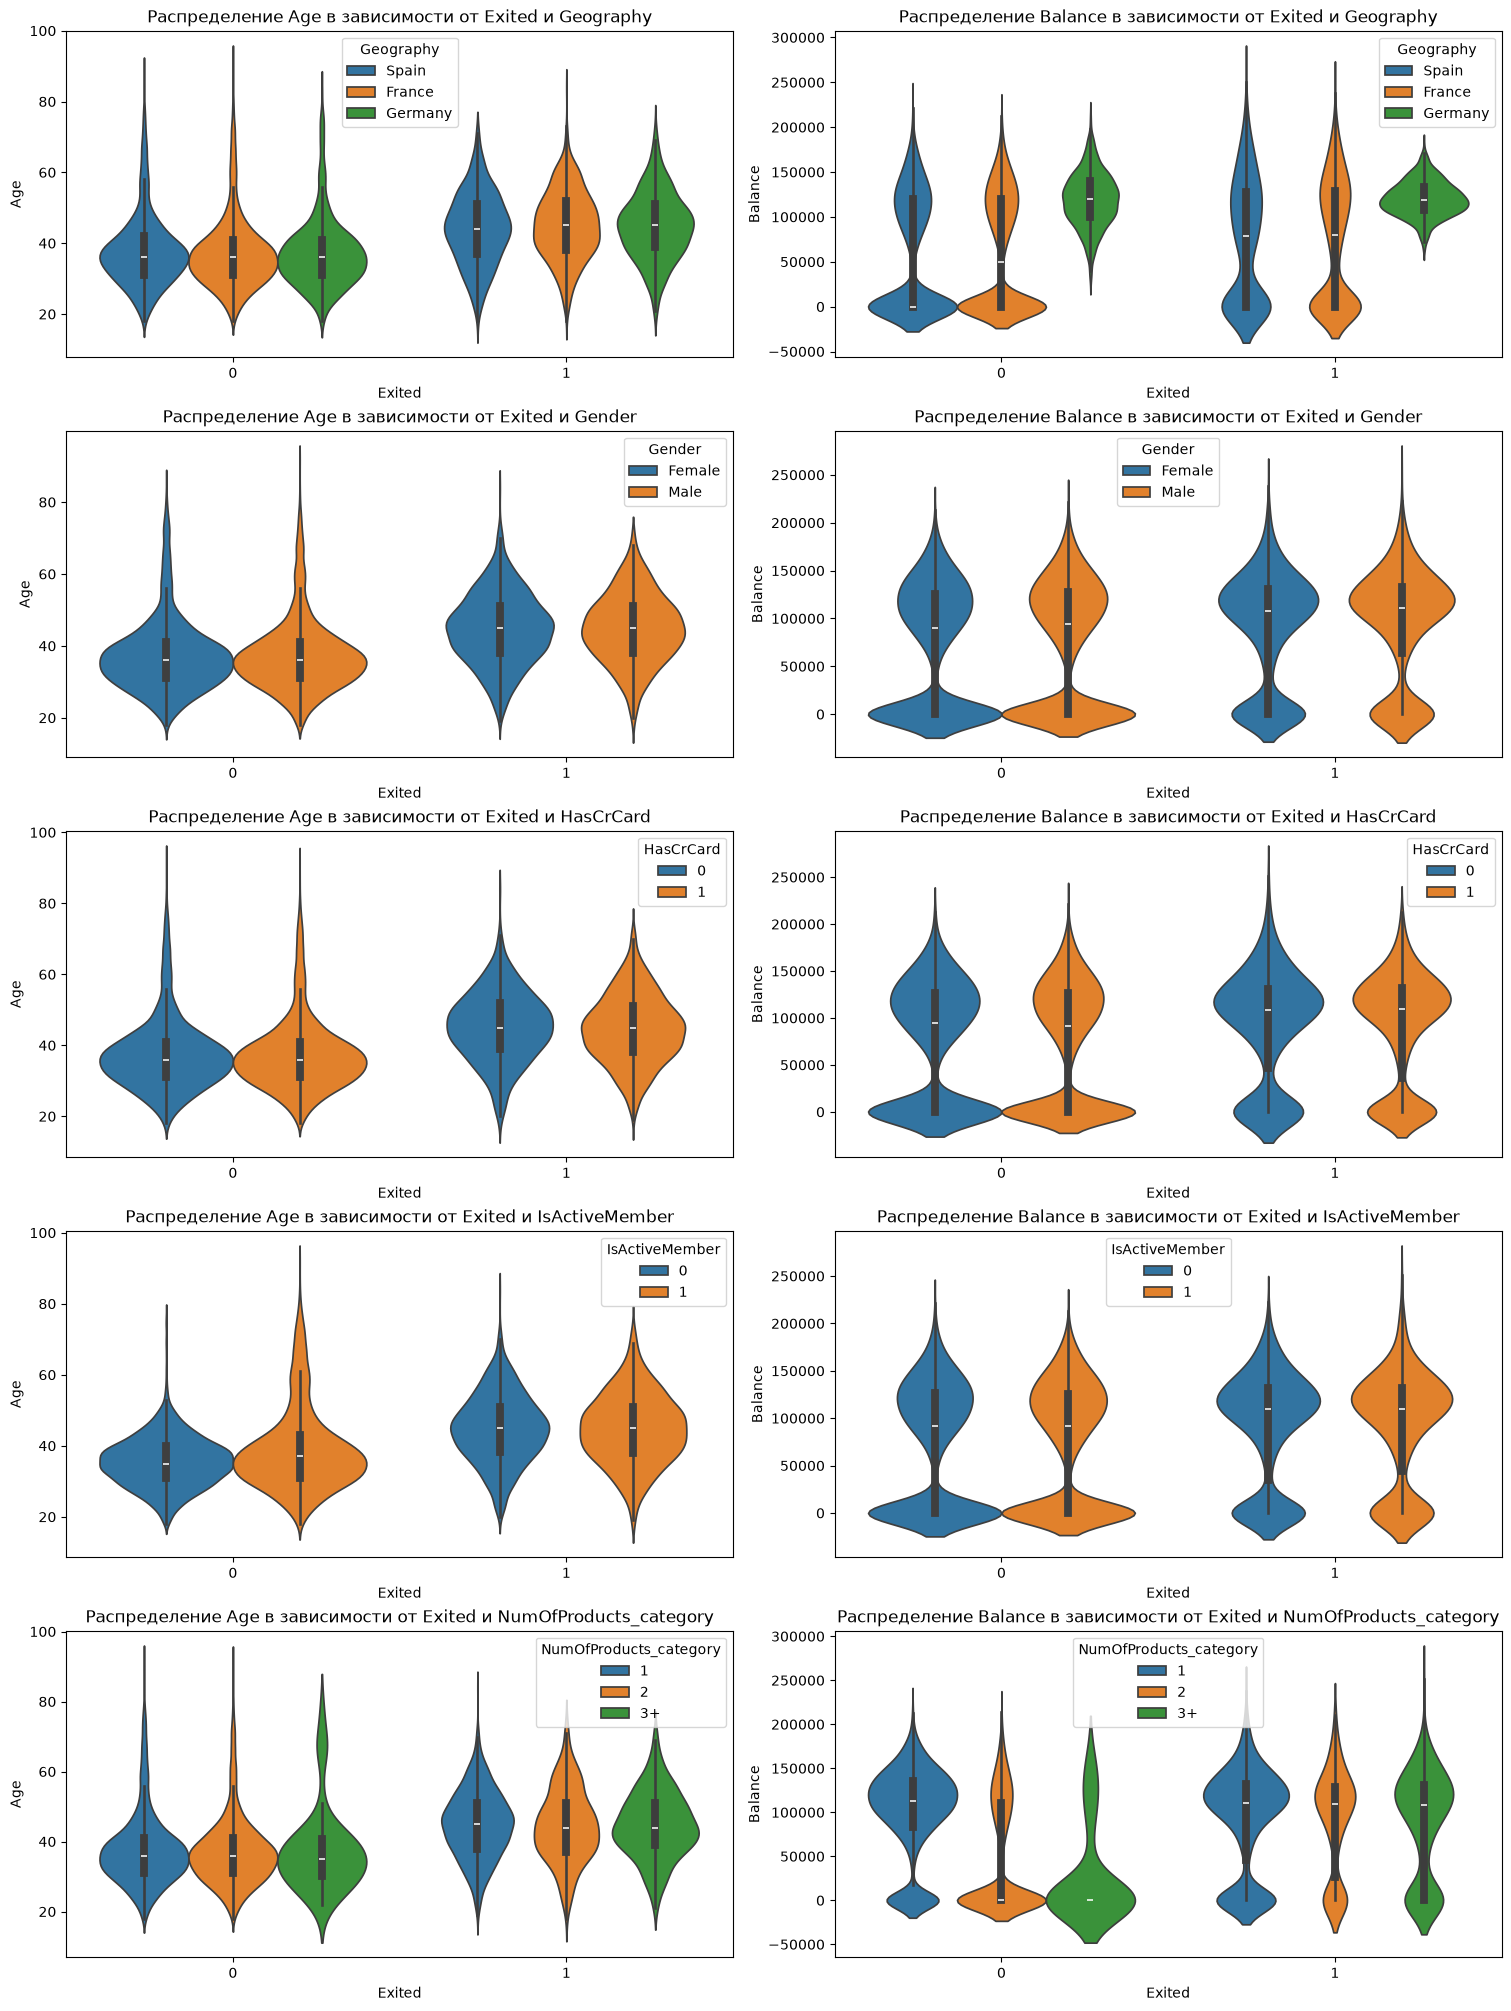

In [ ]:
a = ["Age", "Balance"]

categorical_cols_special = ['Geography', 'Gender', 'HasCrCard', 'IsActiveMember', "NumOfProducts_category"]

fig, ax = plt.subplots(5, 2, figsize=(15, 20), layout = 'constrained')

ax = ax.flatten()

index = 0

for j in range(len(categorical_cols_special)):
    for i in range(len(a)):



        sns.violinplot(x='Exited', y=a[i], hue=categorical_cols_special[j], data=df_prob, ax= ax[index])

        ax[index].set_title(f"Распределение {a[i]} в зависимости от Exited и {categorical_cols_special[j]}")

        index += 1


Строить скрипичный график для 2-х категориальных признаков (```Exited``` и другой категориальный признак) не совсем релевантно и такой график не даст никакой полезной информации. Для категориальных признаков нерелевантно вычислять медиану и невозможно построить распрееление. По этой причине было принято решение рассматривать категориальные признак + Exited вместе с количественным признаком. Наша команда решила взять 2 наиболее влиятельных параметра из предыдушего пункта: ```Age``` и ```Balance```.

По итогу, были построены скрипичные графики по каждому категориальному признаку из представленных в графиках в комбинации с ```Exited```, чтобы показать как меняет распределение количественного признака.

Получилось 10 графиков, но мы обратим внимание на самые интересные выводы:

1. **Age - сильный фактор, на который не имеет связть с  ни один из представленных категориальных признаков.** Можно заметить на 1 строчке графиков, что ни ```Geography```, ни ```HasCrCard``` и др. не меняют глорбально распределение: оставшиеся клиенты у банка в большинстве находятся в диапозоне от 30 до 40 лет, ушедшие - от 40 до 50. Банк систематически теряет более старшее поколение при любых других демографических и поведенческих факторах.

2. **Остаток на счете имеет связь с географией проживания клиента.** Если посмотреть на график "Распределение Balance в зависимости от Exited и Geography", можно заметить следующее: клиенты из Германии обычно имеют средства на счете и вообще не имеют нулевых балансов, что делает немецкий рынок уникальным. С точки зрения бизнеса, следует рассматривать данный сегмент клиентов отдельно, так как поведенческие характеристики и мотивы уйти из банка у них будут отличать от жителей Франции и Испании.

3. **Отток имеет зависимость с количеством продуктов в банке.** Если посмотреть на график "Распределение Balance в зависимости от Exited и NumOfProducts_category" можно заметить, что ушедшие клиенты в общей массе - это пользователи одного продкта и имеющий счет в банке в диапозоне от 100 000 до 150 000 долларов. Можно предположить, что возможно такие клиенты не находят подходящего сберегательного/инвестиционного продкута в банке и поэтому уходят из него. Также можно увидеть что 2 продукта в банке у оставшихся клиентов, у которых в большинстве нулевой баланс.


## Описательные статистики

*Все описательные статистики целевого признака и предикторов:*

* **Описательные статистики целевого признака:**
    * *Меры центральной тенденции:*
        * Среднее `Exited`: 0.2 | То есть только 20% данных по Exited являются оттоком (1).
    * *Меры вариативности:*
        * Количество уникальных значений `Exited`: 2 | Так как `Exited` - бинарный целевой признак.

* **Описательные статистики предикторов:**
    * *Описательные статистики количественных предикторов:*
        * *Меры центральной тенденции:*
            * `CreditScore` (Среднее: 650.53, Медиана: 652.0) | Значения почти равны, что говорит о симметричном распределении. Типичный кредитный рейтинг клиента — около 650.
            * `Age` (Среднее: 38.92, Медиана: 37.0, Мода: 37) | Средний возраст клиентов банка ~39 лет, но чаще всего (мода) встречаются 37-летние клиенты.
            * `Tenure` (Среднее: 5.01, Медиана: 5.0, Мода: 2) | В среднем клиенты остаются с банком 5 лет, однако самая массовая группа — это новые клиенты со стажем всего 2 года.
            * `Balance` (Среднее: 76485.89, Медиана: 97198.54) | Медиана заметно выше среднего. Есть значительная группа клиентов с очень маленьким / нулевым балансом , которая "тянет" среднее значение вниз.
            * `EstimatedSalary` (Среднее: 100090.24, Медиана: 100193.92) | Идеально симметричное распределение. В среднем расчетная зарплата клиентов составляет около 100 тыс.

        * *Меры вариативности:*
            * `CreditScore` (Размах: 500, IQR: 134.0, Дисперсия: 9341.86, Ст. откл: 96.65) | Данные варьируются в широком диапазоне, при этом типичное отклонение от среднего составляет около 97 баллов.
            * `Age` (Размах: 74, IQR: 12.0, Дисперсия: 109.99, Ст. откл: 10.49) | Межквартильный размах всего 12 лет, что говорит о кучности основной массы клиентов вокруг 37-39 лет.
            * `Tenure` (Размах: 10, IQR: 4.0, Дисперсия: 8.36, Ст. откл: 2.89) | Стаж измеряется строго от 0 до 10 лет, типичный разброс от среднего составляет почти 3 года.
            * `Balance` (Размах: 250898.09, IQR: 127644.24, Дисперсия: 3893436175.99, Ст. откл: 62397.41) | Очень высокая дисперсия и стандартное отклонение (62.4 тыс.), что указывает на сильную неоднородность балансов клиентов.
            * `EstimatedSalary` (Размах: 199980.9, IQR: 98386.14, Дисперсия: 3307456784.13, Ст. откл: 57510.49) | Зарплаты имеют высокий размах (почти 200 тыс.) со средним отклонением от центра в 57.5 тыс.

        * *Квартили:*
            * `CreditScore` (Мин: 350.0, Q1: 584.0, Медиана: 652.0, Q3: 718.0, Макс: 850.0) | 50% клиентов (между Q1 и Q3) имеют кредитный рейтинг от 584 до 718.
            * `Age` (Мин: 18.0, Q1: 32.0, Медиана: 37.0, Q3: 44.0, Макс: 92.0) | Четверть клиентов младше 32 лет, а половина (основное ядро) находится в возрасте от 32 до 44 лет.
            * `Tenure` (Мин: 0.0, Q1: 3.0, Медиана: 5.0, Q3: 7.0, Макс: 10.0) | 50% аудитории стабильно сотрудничают с банком от 3 до 7 лет.
            * `Balance` (Мин: 0.0, Q1: 0.0, Медиана: 97198.54, Q3: 127644.24, Макс: 250898.09) | Нижний квартиль (Q1) равен нулю[cite: 5] — это доказывает, что как минимум у 25% клиентов вообще нет средств на счету. У остальных баланс доходит до 250 тыс.
            * `EstimatedSalary` (Мин: 11.58, Q1: 51002.11, Медиана: 100193.92, Q3: 149388.25, Макс: 199992.48) | Основные 50% клиентов зарабатывают от 51 тыс. до 149 тыс., распределение зарплат по квартилям очень симметричное.
        
    * *Описательные статистики категориальных предикторов:*
        * *Меры центральной тенденции:*
            * Мода `Geography`: France | Большая часть клиентов банка проживает во Франции.
            * Мода `NumOfProducts_category`: 1 | Чаще всего клиенты пользуются только одним банковским продуктом.
            * Среднее `Gender`: 0.55 | 55% клиентов имеют значение 1 - это мужчины.
            * Среднее `HasCrCard`: 0.71 | Подавляющее большинство (71%) клиентов владеют кредитной картой.
            * Среднее `IsActiveMember`: 0.52 | Клиентская база делится почти пополам: 52% клиентов являются активными.
        
        * *Меры вариативности:*
            * Уникальные значения номинальных (`Geography`: 3, `NumOfProducts_category`: 3) | Клиенты распределены по трем странам и трем категориям количества продуктов.
            * Уникальные значения бинарных (`Gender`: 2, `HasCrCard`: 2, `IsActiveMember`: 2) | Так как данные признак бинарны (принимают значения 0 или 1).


---

Более подробно расчетный код по описательным статистикам можно узнать в пункта ниже:

### 1. Описательные статистики целевого признака

In [ ]:
#  ヾ( ￣O￣)ツ  ------ меры центральной тенденции ---- ヾ( ￣O￣)ツ

print (f'Cреднее по Exited: {round (df_clean_new["Exited"].mean(), 2)}') # доля "1" по Exited

#  ┌┐(◣_◢)┌┐   ------ меры вариативности ---- ┌┐(◣_◢)┌┐

print (f'Количество уникальных значений по Exited: {df_clean_new["Exited"].nunique()}') # кол-во уникальных значений


Cреднее по Exited: 0.2
Количество уникальных значений по Exited: 2


### 2. Описательные статистики количественных предикторов

#### 2.1 Меры центральной тенденции

In [ ]:
# ▓▒░(°◡°)░▒▓ -------------------------- количественные признаки -------------------------- ▓▒░(°◡°)░▒▓


numeric_cols_2 = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary']

#  ヾ( ￣O￣)ツ  ------ меры центральной тенденции ---- ヾ( ￣O￣)ツ

print ("Среднее:\n")
print (f'⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻')

for i in numeric_cols_2:
    print (f'Среднее по {i}: {round (df_clean_new[i].mean(), 2)}')
print (f'⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻')

print ("Медиана:\n")
print (f'⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻')

for i in numeric_cols_2:
    print (f'Медиана по {i}: {round (df_clean_new[i].median(), 2)}')
print (f'⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻')

print ("Мода:\n")

def g(x):
    return f'Мода по {x}: {df_clean_new[x].mode()[0]}'

print (f'⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻')
print (g("Tenure"))
print (g("Age"))
print (f'⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻')


Среднее:

⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻
Среднее по CreditScore: 650.53
Среднее по Age: 38.92
Среднее по Tenure: 5.01
Среднее по Balance: 76485.89
Среднее по EstimatedSalary: 100090.24
⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻
Медиана:

⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻
Медиана по CreditScore: 652.0
Медиана по Age: 37.0
Медиана по Tenure: 5.0
Медиана по Balance: 97198.54
Медиана по EstimatedSalary: 100193.92
⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻
Мода:

⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻
Мода по Tenure: 2
Мода по Age: 37
⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻


#### 2.2 Квартили

In [ ]:
#  ¯\_(ツ)_/¯   ------ квартили ---- ¯\_(ツ)_/¯

s = [0, 0.25, 0.5, 0.75, 1]

for i in range (len(numeric_cols_2)):
    if i != 0:
        print (f'⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻')
    for j in range (len(s)):
        print (f'○ Квартиль ({s[j]}) по {numeric_cols_2[i]}: {round (df_clean_new[numeric_cols_2[i]].quantile(s[j]), 2)}')


○ Квартиль (0) по CreditScore: 350.0
○ Квартиль (0.25) по CreditScore: 584.0
○ Квартиль (0.5) по CreditScore: 652.0
○ Квартиль (0.75) по CreditScore: 718.0
○ Квартиль (1) по CreditScore: 850.0
⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻
○ Квартиль (0) по Age: 18.0
○ Квартиль (0.25) по Age: 32.0
○ Квартиль (0.5) по Age: 37.0
○ Квартиль (0.75) по Age: 44.0
○ Квартиль (1) по Age: 92.0
⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻
○ Квартиль (0) по Tenure: 0.0
○ Квартиль (0.25) по Tenure: 3.0
○ Квартиль (0.5) по Tenure: 5.0
○ Квартиль (0.75) по Tenure: 7.0
○ Квартиль (1) по Tenure: 10.0
⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻
○ Квартиль (0) по Balance: 0.0
○ Квартиль (0.25) по Balance: 0.0
○ Квартиль (0.5) по Balance: 97198.54
○ Квартиль (0.75) по Balance: 127644.24
○ Квартиль (1) по Balance: 250898.09
⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻
○ Квартиль (0) по EstimatedSalary: 11.58
○ Квартиль (0.25) по EstimatedSalary: 51002.11
○ Квартиль (0.5) по EstimatedSalary: 100193.92
○ Квартиль (0.75) по Esti

#### 2.3 Меры вариативности

In [ ]:
#  ┌┐(◣_◢)┌┐   ------ меры вариативности ---- ┌┐(◣_◢)┌┐

for i in numeric_cols_2:

    if i != "CreditScore":
        print (f'⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻')
    print (f'○ Размах по {i}: {round (df_clean_new[i].max() - df_clean_new[i].min(), 2)}')
    print (f'○ Интерквартильный размах по {i}: {round (df_clean_new[i].quantile(0.75) - df_clean_new[i].quantile(0.25), 2)}')
    print (f'○ Дисперсия по {i}: {round (df_clean_new[i].var(), 2)}')
    print (f'○ Стандартное отклонение по {i}: {round (df_clean_new[i].std(), 2)}')


○ Размах по CreditScore: 500
○ Интерквартильный размах по CreditScore: 134.0
○ Дисперсия по CreditScore: 9341.86
○ Стандартное отклонение по CreditScore: 96.65
⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻
○ Размах по Age: 74
○ Интерквартильный размах по Age: 12.0
○ Дисперсия по Age: 109.99
○ Стандартное отклонение по Age: 10.49
⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻
○ Размах по Tenure: 10
○ Интерквартильный размах по Tenure: 4.0
○ Дисперсия по Tenure: 8.36
○ Стандартное отклонение по Tenure: 2.89
⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻
○ Размах по Balance: 250898.09
○ Интерквартильный размах по Balance: 127644.24
○ Дисперсия по Balance: 3893436175.99
○ Стандартное отклонение по Balance: 62397.41
⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻
○ Размах по EstimatedSalary: 199980.9
○ Интерквартильный размах по EstimatedSalary: 98386.14
○ Дисперсия по EstimatedSalary: 3307456784.13
○ Стандартное отклонение по EstimatedSalary: 57510.49


### 3. Описательные статистики количественных предикторов

#### 3.1 Меры центральной тенденции

In [ ]:
# ▓▒░(°◡°)░▒▓ -------------------------- категориальные признаки -------------------------- ▓▒░(°◡°)░▒▓

categorical_cols_2 = ['Geography', "NumOfProducts_category"]

categorical_cols_binar = ['Gender', 'HasCrCard', 'IsActiveMember']

df_prob_2 = df_clean_new.copy()

def w(x):
   if x == "Male":
    return 1
   else:
    return 0

df_prob_2["Gender"] = df_prob_2["Gender"].apply(w)

#  ヾ( ￣O￣)ツ  ------ меры центральной тенденции ---- ヾ( ￣O￣)ツ

print (" ---- Номинальные категориальные ----\n")

print ("Мода:\n")

def g(x):
    return f'Мода по {x}: {df_clean_new[x].mode()[0]}'

print (f'⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻')
for i in categorical_cols_2:
    print (g(i))
print (f'⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻')

print (" ---- Бинарные категориальные ----\n")

print ("Среднее:\n")
print (f'⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻')

for i in categorical_cols_binar:
    print (f'Среднее по {i}: {round (df_prob_2[i].mean(), 2)}')
print (f'⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻')


 ---- Номинальные категориальные ----

Мода:

⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻
Мода по Geography: France
Мода по NumOfProducts_category: 1
⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻
 ---- Бинарные категориальные ----

Среднее:

⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻
Среднее по Gender: 0.55
Среднее по HasCrCard: 0.71
Среднее по IsActiveMember: 0.52
⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻


#### 3.2 Меры вариативности

In [ ]:
#  ┌┐(◣_◢)┌┐   ------ меры вариативности ---- ┌┐(◣_◢)┌┐

print (" ---- Номинальные категориальные ----\n")

print ("Количество уникальных значений:\n")

print (f'⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻')
for i in categorical_cols_2:
    print (f'Количество уникальных признаков по {i}: {round (df_clean_new[i].nunique(), 2)}')
print (f'⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻')

print (" ---- Номинальные категориальные ----\n")

print ("Количество уникальных значений:\n")

print (f'⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻')
for i in categorical_cols_binar:
    print (f'Количество уникальных признаков по {i}: {round (df_clean_new[i].nunique(), 2)}')
print (f'⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻')

 ---- Номинальные категориальные ----

Количество уникальных значений:

⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻
Количество уникальных признаков по Geography: 3
Количество уникальных признаков по NumOfProducts_category: 3
⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻
 ---- Номинальные категориальные ----

Количество уникальных значений:

⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻
Количество уникальных признаков по Gender: 2
Количество уникальных признаков по HasCrCard: 2
Количество уникальных признаков по IsActiveMember: 2
⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻⎻


____

## 3. КТ2: Подготовка данных и Моделирование

### 3.1. Перекодирование данных

Бинарные данные

In [ ]:
len(df_clean_new.columns)

14

In [ ]:
df_clean_new = pd.get_dummies(data = df_clean_new, columns = ['Gender', 'HasCrCard', 'IsActiveMember'])

In [ ]:
len(df_clean_new.columns)

17

Порядковые признаки

In [ ]:
df_clean_new['NumOfProducts_category'].value_counts()

NumOfProducts_category
1     5084
2     4590
3+     326
Name: count, dtype: int64

In [ ]:
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder(categories=[['1', '2', '3+']])
df_clean_new['NumOfProducts_category'] = encoder.fit_transform(df_clean_new[['NumOfProducts_category']])


In [ ]:
df_clean_new['NumOfProducts_category'].value_counts()

NumOfProducts_category
0.0    5084
1.0    4590
2.0     326
Name: count, dtype: int64

### 3.2. Корреляционный анализ

Топ 5 признаков по силе связи с целевой переменной

In [ ]:
df_clean_new.drop(columns='Exited').corrwith(df_clean_new['Exited'], numeric_only= True).sort_values(key = abs, ascending = False).iloc[0:5]

Age                 0.285323
IsActiveMember_0    0.156128
IsActiveMember_1   -0.156128
Balance             0.118533
Gender_Male        -0.106512
dtype: float64

матрица корелляций

In [ ]:
df_clean_new.corr(numeric_only=True, method = 'pearson')['Exited'].sort_values()

IsActiveMember_1         -0.156128
Gender_Male              -0.106512
NumOfProducts_category   -0.070736
CreditScore              -0.027094
RowNumber                -0.016571
Tenure                   -0.014001
HasCrCard_1              -0.007138
CustomerId               -0.006248
HasCrCard_0               0.007138
EstimatedSalary           0.012097
Gender_Female             0.106512
Balance                   0.118533
IsActiveMember_0          0.156128
Age                       0.285323
Exited                    1.000000
Name: Exited, dtype: float64

In [ ]:
df_clean_new.corr(numeric_only=True, method = 'spearman')['Exited'].sort_values()

IsActiveMember_1         -0.156128
NumOfProducts_category   -0.125418
Gender_Male              -0.106512
CreditScore              -0.023289
RowNumber                -0.016571
Tenure                   -0.013978
HasCrCard_1              -0.007138
CustomerId               -0.006264
HasCrCard_0               0.007138
EstimatedSalary           0.012081
Gender_Female             0.106512
Balance                   0.111110
IsActiveMember_0          0.156128
Age                       0.323968
Exited                    1.000000
Name: Exited, dtype: float64

In [ ]:
from sklearn.preprocessing import StandardScaler



In [ ]:
df_clean_new.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Age,Tenure,Balance,EstimatedSalary,Exited,NumOfProducts_category,Gender_Female,Gender_Male,HasCrCard_0,HasCrCard_1,IsActiveMember_0,IsActiveMember_1
0,1,15634602,Hargrave,619,France,42,2,0.00,101348.88,1,0.0,True,False,False,True,False,True
1,2,15647311,Hill,608,Spain,41,1,83807.86,112542.58,0,0.0,True,False,True,False,False,True
2,3,15619304,Onio,502,France,42,8,159660.80,113931.57,1,2.0,True,False,False,True,True,False
3,4,15701354,Boni,699,France,39,1,0.00,93826.63,0,1.0,True,False,True,False,True,False
4,5,15737888,Mitchell,850,Spain,43,2,125510.82,79084.10,0,0.0,True,False,False,True,False,True


In [ ]:
standartizer = StandardScaler(copy = False)
model_data = df_clean_new.copy()
model_data[['CreditScore', "Age", 'Tenure', 'Balance', 'EstimatedSalary']] = standartizer.fit_transform(model_data[['CreditScore', "Age", 'Tenure', 'Balance', 'EstimatedSalary']])
model_data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Age,Tenure,Balance,EstimatedSalary,Exited,NumOfProducts_category,Gender_Female,Gender_Male,HasCrCard_0,HasCrCard_1,IsActiveMember_0,IsActiveMember_1
0,1,15634602,Hargrave,-0.326221,France,0.293517,-1.041760,-1.225848,0.021886,1,0.0,True,False,False,True,False,True
1,2,15647311,Hill,-0.440036,Spain,0.198164,-1.387538,0.117350,0.216534,0,0.0,True,False,True,False,False,True
2,3,15619304,Onio,-1.536794,France,0.293517,1.032908,1.333053,0.240687,1,2.0,True,False,False,True,True,False
3,4,15701354,Boni,0.501521,France,0.007457,-1.387538,-1.225848,-0.108918,0,1.0,True,False,True,False,True,False
4,5,15737888,Mitchell,2.063884,Spain,0.388871,-1.041760,0.785728,-0.365276,0,0.0,True,False,False,True,False,True


Очистим датасет от переменных которые не имеют информационной ценности для нашей модели(RowNumber, CustomerId, а также Surname поскольку он является номинальным, то при getdummies таблица может очень сильно разрасти).

Также еще перекодируем географию(хоть и в тз это не требуется, поскольку говорилось лишь об перекодировании бинарных и порядковых, но мы все равно сделаем для лучшего результата).

In [ ]:
model_data.Geography.value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [ ]:
model_data = model_data.drop(columns = ['RowNumber',	'CustomerId',	'Surname'])

model_data = pd.get_dummies(data = model_data, columns = ['Geography'])

model_data.head()

,CreditScore,Age,Tenure,Balance,EstimatedSalary,Exited,NumOfProducts_category,Gender_Female,Gender_Male,HasCrCard_0,HasCrCard_1,IsActiveMember_0,IsActiveMember_1,Geography_France,Geography_Germany,Geography_Spain
0,-0.326221,0.293517,-1.041760,-1.225848,0.021886,1,0.0,True,False,False,True,False,True,True,False,False
1,-0.440036,0.198164,-1.387538,0.117350,0.216534,0,0.0,True,False,True,False,False,True,False,False,True
2,-1.536794,0.293517,1.032908,1.333053,0.240687,1,2.0,True,False,False,True,True,False,True,False,False
3,0.501521,0.007457,-1.387538,-1.225848,-0.108918,0,1.0,True,False,True,False,True,False,True,False,False
4,2.063884,0.388871,-1.041760,0.785728,-0.365276,0,0.0,True,False,False,True,False,True,False,False,True


___

In [ ]:
model = LogisticRegression()

Xtrain, Xtest, ytrain, ytest = train_test_split(model_data.drop(columns= ['Exited']), model_data['Exited'], train_size= 0.8, random_state= 42, stratify= model_data['Exited'])

model.fit(Xtrain, ytrain)

pd.DataFrame(model.coef_)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,-0.085822,0.733483,-0.018949,0.138916,0.049335,-0.237797,0.01749,-0.508176,-0.21025,-0.280436,0.268392,-0.759077,-0.459292,0.381845,-0.413239


Здесь написать фомрулу модели

In [ ]:

y_pred = model.predict(Xtest)
y_prob = model.predict_proba(Xtest)[:, 1]

from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, log_loss,
    precision_recall_curve, auc
)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

logloss = log_loss(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)
precision_points, recall_points, _ = precision_recall_curve(y_test, y_prob)
pr_auc = auc(recall_points, precision_points)

#  Вывод результатов
print("=== МЕТРИКИ КЛАССИФИКАЦИИ ===")
print("Матрица ошибок (Confusion Matrix):")
print(f"  [TN: {tn} | FP: {fp}]")
print(f"  [FN: {fn} | TP: {tp}]")
print(f"Accuracy (Доля правильных ответов):  {accuracy:.4f}")
print(f"Precision (Точность):                {precision:.4f}")
print(f"Recall (Полнота):                    {recall:.4f}")
print(f"F1-score:                            {f1:.4f}")
print("\n=== ВЕРОЯТНОСТНЫЕ И ПОРОГОВЫЕ МЕТРИКИ ===")
print(f"Log Loss (Кросс-энтропия):           {logloss:.4f}")
print(f"ROC-AUC (Площадь под ROC-кривой):    {roc_auc:.4f}")
print(f"PR-AUC (Площадь под PR-кривой):      {pr_auc:.4f}")


=== МЕТРИКИ КЛАССИФИКАЦИИ ===
Матрица ошибок (Confusion Matrix):
  [TN: 1502 | FP: 105]
  [FN: 364 | TP: 29]
Accuracy (Доля правильных ответов):  0.7655
Precision (Точность):                0.2164
Recall (Полнота):                    0.0738
F1-score:                            0.1101

=== ВЕРОЯТНОСТНЫЕ И ПОРОГОВЫЕ МЕТРИКИ ===
Log Loss (Кросс-энтропия):           0.5753
ROC-AUC (Площадь под ROC-кривой):    0.5016
PR-AUC (Площадь под PR-кривой):      0.2010
